In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("../images", exist_ok=True)

In [2]:
loans = pd.read_csv("../data/loan_clean.csv", parse_dates=["issue_d"])
print(loans.shape)

(1343585, 31)


## The overall default rate

In [3]:
overall = loans["default_flag"].mean() * 100
print(f"Overall default rate: {overall:.2f}%")

Overall default rate: 19.96%


In [4]:
def rate_chart(series, title, xlabel, filename, rotate=0, figsize=(9, 4)):
    ax = series.plot(kind="bar", color="steelblue", figsize=figsize)
    ax.axhline(overall, color="red", linestyle="--", label=f"Overall {overall:.1f}%")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Default rate (%)")
    ax.legend()
    plt.xticks(rotation=rotate)
    plt.savefig(f"../images/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

## Default rate by grade

In [6]:
by_grade = (loans.groupby("grade")["default_flag"].mean() * 100).round(2)
by_grade

grade
A     6.04
B    13.39
C    22.44
D    30.39
E    38.49
F    45.21
G    49.94
Name: default_flag, dtype: float64

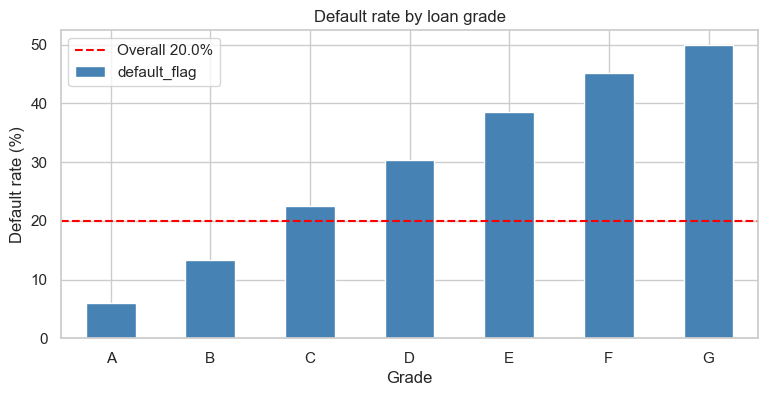

In [7]:
rate_chart(by_grade, "Default rate by loan grade", "Grade", "default_by_grade.png")

In [8]:
grade_table = loans.groupby("grade").agg(
    loans=("default_flag", "size"),
    defaults=("default_flag", "sum"),
    default_rate=("default_flag", "mean")
)
grade_table["default_rate"] = (grade_table["default_rate"] * 100).round(2)
grade_table["share_of_loans_%"] = (grade_table["loans"] / grade_table["loans"].sum() * 100).round(2)
grade_table["share_of_defaults_%"] = (grade_table["defaults"] / grade_table["defaults"].sum() * 100).round(2)
grade_table

,loans,defaults,default_rate,share_of_loans_%,share_of_defaults_%
grade,,,,,
A,234932,14196,6.04,17.49,5.29
B,392360,52535,13.39,29.20,19.59
C,381138,85533,22.44,28.37,31.89
D,200581,60951,30.39,14.93,22.73
E,93481,35983,38.49,6.96,13.42
F,31998,14465,45.21,2.38,5.39
G,9095,4542,49.94,0.68,1.69


## Default rate by loan purpose

In [9]:
by_purpose = (loans.groupby("purpose")["default_flag"].mean() * 100).round(2).sort_values(ascending=False)
by_purpose

purpose
small_business        29.70
renewable_energy      23.71
moving                23.37
house                 21.92
medical               21.79
debt_consolidation    21.14
other                 21.04
vacation              19.16
major_purchase        18.60
home_improvement      17.72
educational           17.34
credit_card           16.93
car                   14.68
wedding               12.17
Name: default_flag, dtype: float64

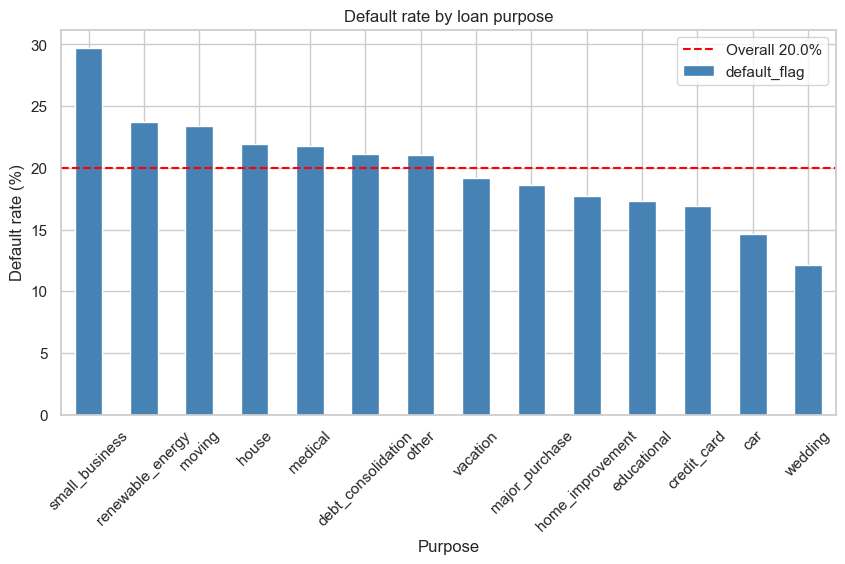

In [10]:
rate_chart(by_purpose, "Default rate by loan purpose", "Purpose",
           "default_by_purpose.png", rotate=45, figsize=(10, 5))

## Default rate by state

In [11]:
by_state = (loans.groupby("addr_state")["default_flag"].mean() * 100).round(2).sort_values(ascending=False)
print("Highest 5:")
print(by_state.head(5))
print("Lowest 5:")
print(by_state.tail(5))

Highest 5:
addr_state
MS    26.08
NE    25.15
AR    24.10
AL    23.60
OK    23.47
Name: default_flag, dtype: float64
Lowest 5:
addr_state
OR    14.39
IA    14.29
VT    13.97
ME    13.86
DC    13.24
Name: default_flag, dtype: float64


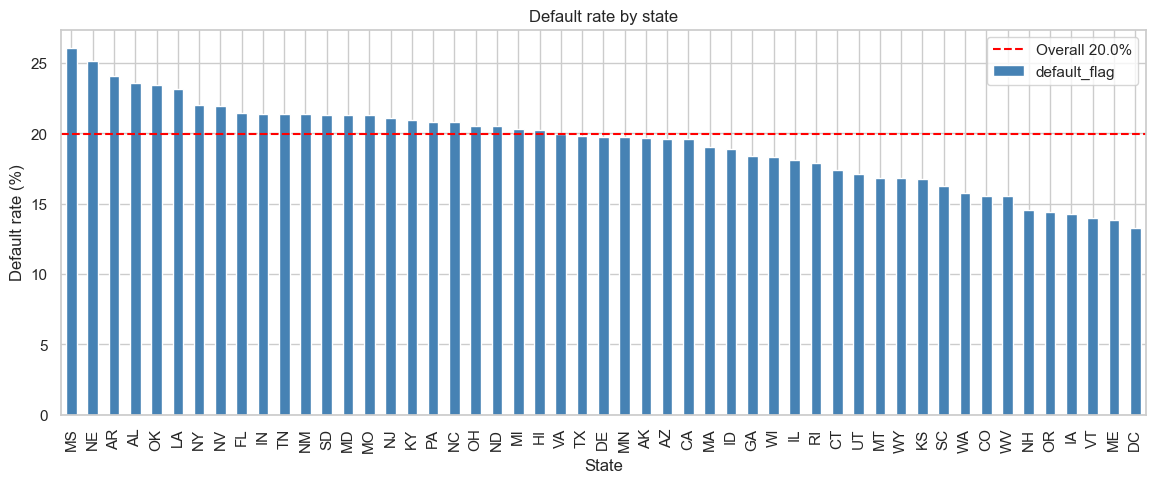

In [12]:
rate_chart(by_state, "Default rate by state", "State",
           "default_by_state.png", rotate=90, figsize=(14, 5))

In [13]:
loans["addr_state"].value_counts().tail(8)

addr_state
AK    3185
WY    2917
SD    2762
VT    2649
ME    2027
ID    1672
ND    1600
IA       7
Name: count, dtype: int64

## Default rate by year (vintage)

In [14]:
by_year = (loans.groupby("issue_year")["default_flag"].mean() * 100).round(2)
by_year

issue_year
2007    17.93
2008    15.64
2009    12.57
2010    12.87
2011    15.17
2012    16.19
2013    15.60
2014    18.45
2015    20.18
2016    23.29
2017    23.12
2018    15.74
Name: default_flag, dtype: float64

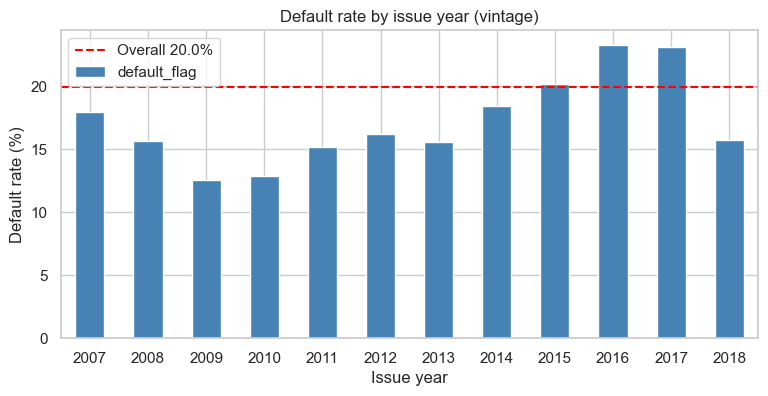

In [15]:
rate_chart(by_year, "Default rate by issue year (vintage)", "Issue year", "default_by_year.png")

## Default rate by income and DTI

In [16]:
income_order = ["<40K", "40-70K", "70-100K", "100-150K", "150K+"]
dti_order = ["0-10", "10-20", "20-30", "30+"]

by_income = (loans.groupby("income_bucket")["default_flag"].mean() * 100).reindex(income_order).round(2)
by_dti = (loans.groupby("dti_bucket")["default_flag"].mean() * 100).reindex(dti_order).round(2)

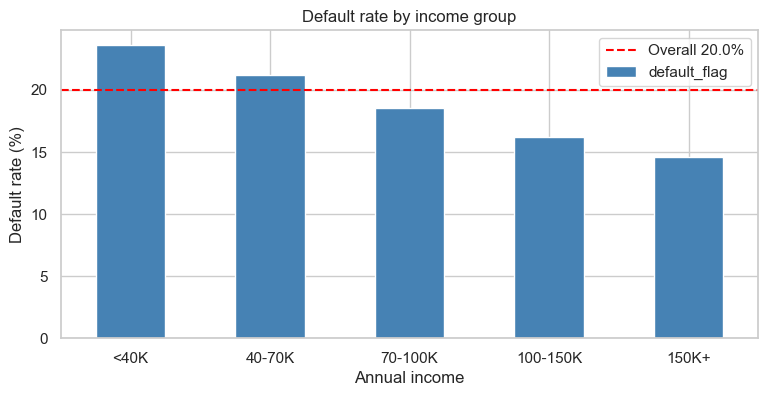

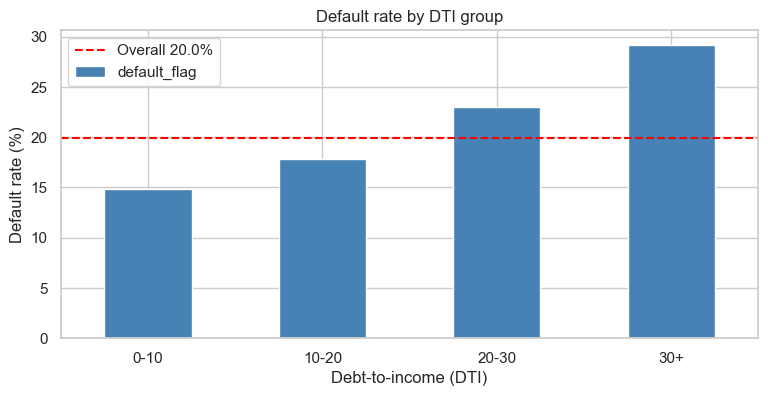

In [17]:
rate_chart(by_income, "Default rate by income group", "Annual income", "default_by_income.png")
rate_chart(by_dti, "Default rate by DTI group", "Debt-to-income (DTI)", "default_by_dti.png")

## Default rate by loan term

In [18]:
by_term = (loans.groupby("term_months")["default_flag"].mean() * 100).round(2)
by_term

term_months
36    15.99
60    32.46
Name: default_flag, dtype: float64

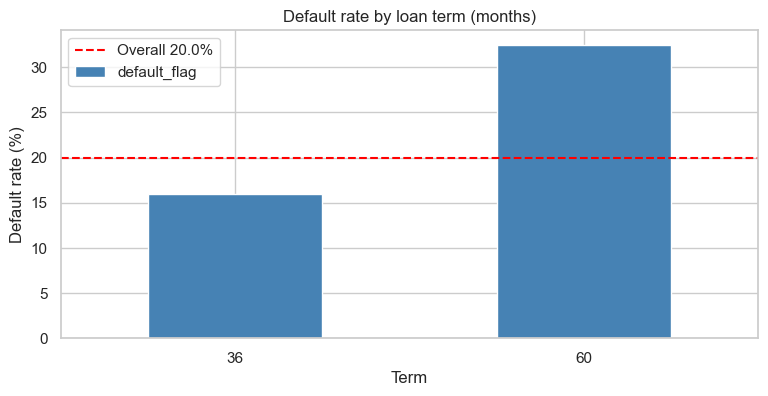

In [19]:
rate_chart(by_term, "Default rate by loan term (months)", "Term", "default_by_term.png")

## Default rate by credit score

In [20]:
loans["fico_band"] = pd.cut(loans["fico_avg"],
                            bins=[0, 660, 700, 740, 780, 850],
                            labels=["<660", "660-699", "700-739", "740-779", "780+"])

by_fico = (loans.groupby("fico_band", observed=True)["default_flag"].mean() * 100).round(2)
by_fico

fico_band
<660        0.00
660-699    23.59
700-739    16.06
740-779    10.56
780+        7.10
Name: default_flag, dtype: float64

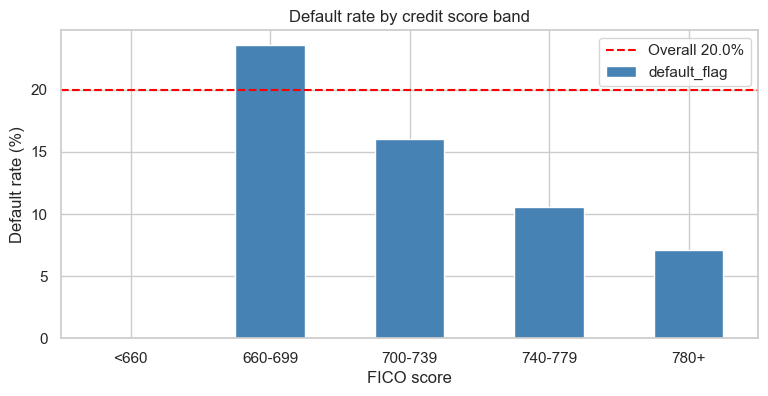

In [21]:
rate_chart(by_fico, "Default rate by credit score band", "FICO score", "default_by_fico.png")

## Key findings

1. About X% of loans with a final outcome defaulted.
2. Default rate rises from X% (grade A) to X% (grade G).
3. Grade [..] holds X% of all loans but X% of all defaults.
4. [Purpose] has the highest default rate, and [purpose] the lowest.
5. Recent years look better, but those loans are not fully matured yet.